# GIAI ĐOẠN 3: RÚT TRÍCH VÀ BIẾN ĐỔI ĐẶC TRƯNG (FEATURE ENGINEERING - RFM)
## Đề tài: Phân khúc khách hàng bán lẻ trực tuyến bằng RFM và Học máy (Online Retail II)

Tập notebook này chịu trách nhiệm trích xuất bộ ba chỉ số hành vi khách hàng **RFM (Recency - Frequency - Monetary)** từ dữ liệu giao dịch sạch, phân tích độ lệch phân phối (Skewness), áp dụng phép biến đổi log (`log1p`) và chuẩn hóa đặc trưng (`StandardScaler`) phục vụ huấn luyện các mô hình học máy.

---
### Các bước thực hiện:
1. **Nạp dữ liệu sạch `data/data_clean.csv`:** Toàn bộ 398,971 giao dịch đã qua tiền xử lý.
2. **Tính toán bộ chỉ số RFM theo từng CustomerID:**
   - $\\text{Recency} (R)$: Số ngày tính từ lần mua gần nhất đến mốc khảo sát (`snapshot_date = max(InvoiceDate) + 1 ngày`).
   - $\\text{Frequency} (F)$: Tổng số lượng hóa đơn duy nhất mà khách hàng đã thực hiện.
   - $\\text{Monetary} (M)$: Tổng số tiền chi tiêu tích lũy của khách hàng ($\\sum \\text{TotalPrice}$).
3. **Khảo sát phân phối thống kê & Độ lệch (Skewness):** Đánh giá độ lệch phải cực đoan của RFM.
4. **Phân chia tập đặc trưng RFM (Train / Val / Test):** Đảm bảo tính nhất quán với tập chia từ bước tiền xử lý.
5. **Xử lý độ lệch (Log-Transformation) & Chuẩn hóa (StandardScaler):** Áp dụng $\\ln(1 + x)$ và chuẩn hóa thang đo z-score chỉ fit trên tập Train (chống Data Leakage).
6. **Trực quan hóa không gian đặc trưng RFM:** Khảo sát ma trận tương quan và không gian 2D/3D của các đặc trưng.
7. **Xuất kết quả & Xuất hình ảnh:** Xuất toàn bộ file dữ liệu đặc trưng `data/rfm_data.csv`, `rfm_train.csv`, `rfm_val.csv`, `rfm_test.csv`, bảng chỉ số thống kê và các ảnh biểu đồ trực quan.

In [1]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động định vị và chuyển working directory về thư mục gốc Do_an_CuoiKy
current_dir = os.path.abspath(os.getcwd())
while current_dir and not os.path.exists(os.path.join(current_dir, "data")):
    parent = os.path.dirname(current_dir)
    if parent == current_dir:
        break
    current_dir = parent
if os.path.exists(os.path.join(current_dir, "data")):
    os.chdir(current_dir)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Thư mục làm việc hiện tại: {os.getcwd()}")

✅ Thư mục làm việc hiện tại: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy


### 1. Nạp dữ liệu giao dịch sạch `data/data_clean.csv`

In [2]:
df_clean = pd.read_csv("data/data_clean.csv")
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['CustomerID'] = df_clean['CustomerID'].astype(str)

print(f"Số lượng giao dịch sạch nạp vào: {len(df_clean):,} dòng")
print(f"Số lượng khách hàng duy nhất   : {df_clean['CustomerID'].nunique():,} khách hàng")

Số lượng giao dịch sạch nạp vào: 398,971 dòng
Số lượng khách hàng duy nhất   : 4,275 khách hàng


### 2. Tính toán bộ ba chỉ số RFM (Recency, Frequency, Monetary)
* **Snapshot Date:** Chọn ngày sau giao dịch cuối cùng 1 ngày (`max(InvoiceDate) + 1 ngày`).
* **Recency:** `(snapshot_date - max(InvoiceDate)).dt.days`
* **Frequency:** `InvoiceNo.nunique()`
* **Monetary:** `TotalPrice.sum()`

In [3]:
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"📅 Mốc thời gian tham chiếu (Snapshot Date): {snapshot_date}")

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
}).reset_index()

rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

# Lọc bỏ Monetary <= 0 nếu có phát sinh ngoại lệ
rfm = rfm[rfm['Monetary'] > 0].copy()

print(f"✅ Đã trích xuất đặc trưng RFM cho {len(rfm):,} khách hàng.")
print("--- 5 DÒNG ĐẶC TRƯNG RFM ĐẦU TIÊN ---")
print(rfm.head())

📅 Mốc thời gian tham chiếu (Snapshot Date): 2010-12-10 20:01:00


✅ Đã trích xuất đặc trưng RFM cho 4,275 khách hàng.
--- 5 DÒNG ĐẶC TRƯNG RFM ĐẦU TIÊN ---
  CustomerID  Recency  Frequency  Monetary
0      12346      165         11    372.86
1      12347        3          2   1323.32
2      12348       74          1    221.16
3      12349       43          2   2221.14
4      12351       11          1    300.93


### 3. Khám phá phân phối thống kê & Đo lường độ lệch (Skewness)

In [4]:
rfm_desc = rfm[["Recency", "Frequency", "Monetary"]].describe()
raw_skew = rfm[["Recency", "Frequency", "Monetary"]].skew()

skewness_df = pd.DataFrame({
    'Thuoc_tinh': ['Recency', 'Frequency', 'Monetary'],
    'Do_lech_Skewness_Tho': raw_skew.values,
    'Danh_gia': ['Lệch phải vừa phải' if s < 2 else 'Lệch phải cực đoan' for s in raw_skew.values]
})

print("--- THỐNG KÊ MÔ TẢ ĐẶC TRƯNG RFM THÔ ---")
print(rfm_desc)
print("\n--- ĐỘ LỆCH SKEWNESS CỦA CÁC ĐẶC TRƯNG RFM ---")
print(skewness_df)

--- THỐNG KÊ MÔ TẢ ĐẶC TRƯNG RFM THÔ ---
           Recency    Frequency       Monetary
count  4275.000000  4275.000000    4275.000000
mean     90.603041     4.418246    1942.872847
std      96.399335     7.898931    8382.079316
min       1.000000     1.000000       2.950000
25%      18.000000     1.000000     305.280000
50%      52.000000     2.000000     687.310000
75%     136.000000     5.000000    1676.860000
max     374.000000   183.000000  323860.530000

--- ĐỘ LỆCH SKEWNESS CỦA CÁC ĐẶC TRƯNG RFM ---
  Thuoc_tinh  Do_lech_Skewness_Tho            Danh_gia
0    Recency              1.293005  Lệch phải vừa phải
1  Frequency              9.941921  Lệch phải cực đoan
2   Monetary             24.221955  Lệch phải cực đoan


### 4. Trực quan hóa phân phối gốc của bộ đặc trưng RFM

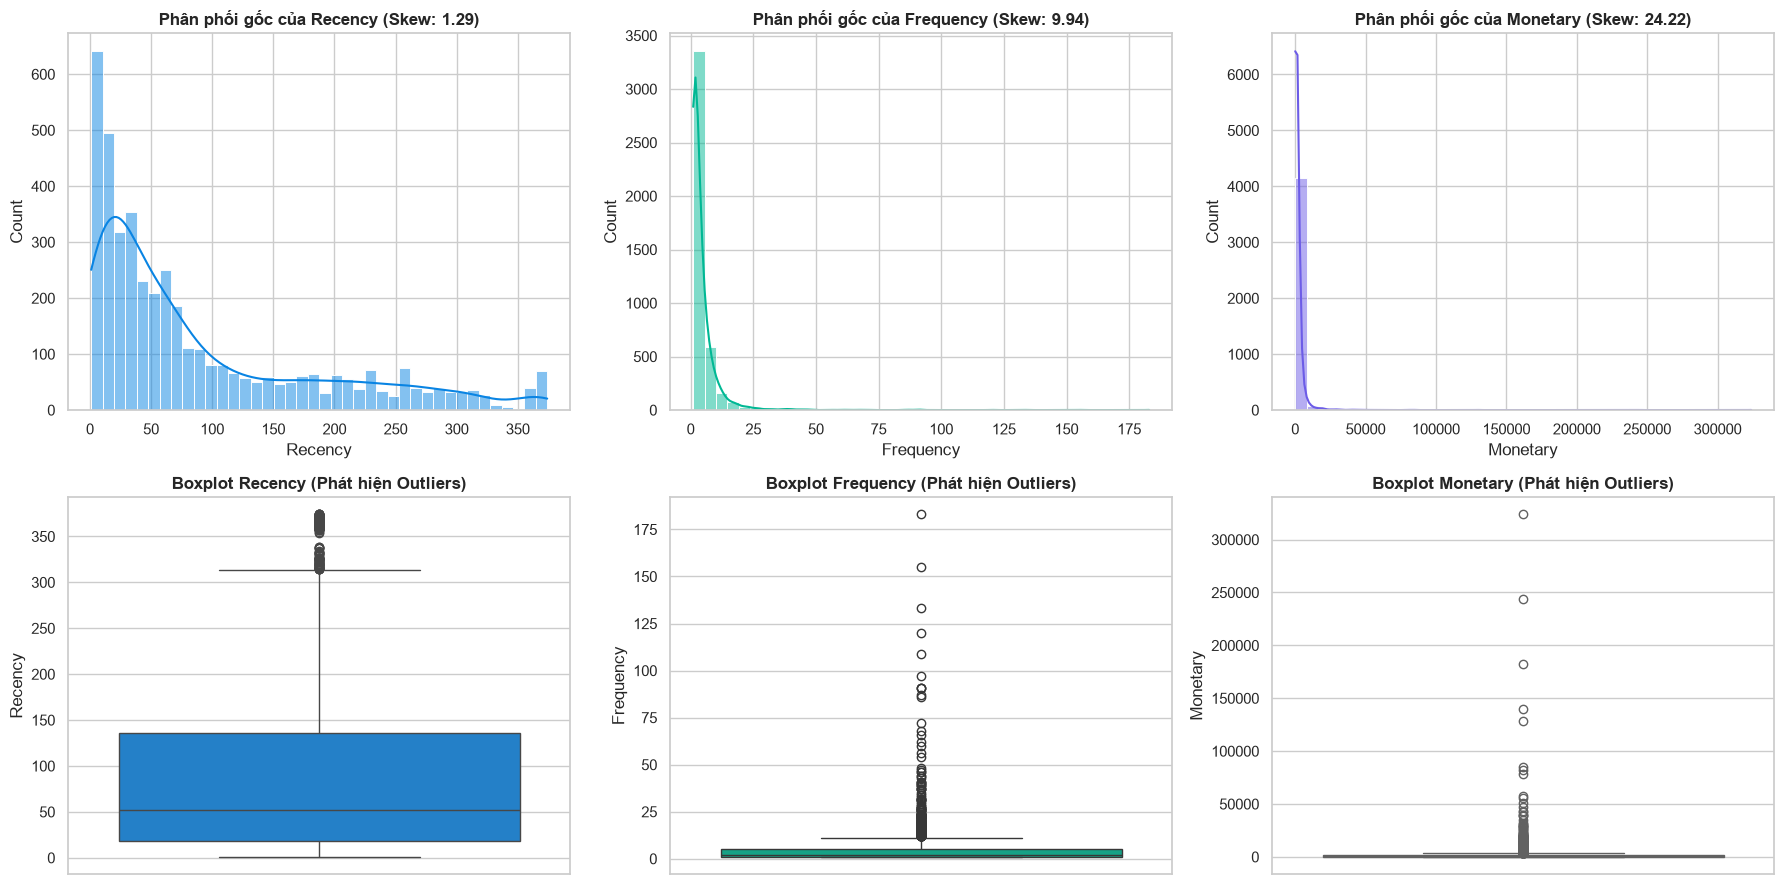

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
features = ['Recency', 'Frequency', 'Monetary']
colors = ['#0984e3', '#00b894', '#6c5ce7']

for i, col in enumerate(features):
    # Histogram & KDE
    sns.histplot(rfm[col], kde=True, ax=axes[0, i], color=colors[i], bins=40)
    axes[0, i].set_title(f'Phân phối gốc của {col} (Skew: {raw_skew[col]:.2f})', fontweight='bold')
    
    # Boxplot
    sns.boxplot(y=rfm[col], ax=axes[1, i], color=colors[i])
    axes[1, i].set_title(f'Boxplot {col} (Phát hiện Outliers)', fontweight='bold')

plt.tight_layout()
plt.show()

### 5. Phân chia tập dữ liệu RFM (Train / Validation / Test)
Tuân thủ nguyên tắc chống rò rỉ dữ liệu (Anti-Data Leakage), phân chia tập khách hàng RFM theo tỷ lệ 64% Train / 16% Validation / 20% Test.

In [6]:
# Phân chia RFM: 80% Train_Val / 20% Test, sau đó 80% Train / 20% Val
train_val_rfm, test_rfm = train_test_split(rfm, test_size=0.20, random_state=42)
train_rfm, val_rfm = train_test_split(train_val_rfm, test_size=0.20, random_state=42)

train_rfm = train_rfm.copy()
val_rfm = val_rfm.copy()
test_rfm = test_rfm.copy()

print(f"Tập RFM Train      : {len(train_rfm):,} khách hàng ({len(train_rfm)/len(rfm)*100:.1f}%)")
print(f"Tập RFM Validation : {len(val_rfm):,} khách hàng ({len(val_rfm)/len(rfm)*100:.1f}%)")
print(f"Tập RFM Test       : {len(test_rfm):,} khách hàng ({len(test_rfm)/len(rfm)*100:.1f}%)")

Tập RFM Train      : 2,736 khách hàng (64.0%)
Tập RFM Validation : 684 khách hàng (16.0%)
Tập RFM Test       : 855 khách hàng (20.0%)


### 6. Xử lý độ lệch (Log-Transform) & Chuẩn hóa dữ liệu (StandardScaler)
1. **Biến đổi Log-transform:** Áp dụng hàm $\\ln(1 + x)$ trên cả ba đặc trưng để đưa phân phối về dạng tiệm cận chuẩn (Gaussian-like).
2. **Chuẩn hóa StandardScaler:** $\\text{z} = \\frac{x - \\mu}{\\sigma}$. `StandardScaler` được **fit duy nhất trên tập Train**, sau đó áp dụng `transform` lên Validation và Test.

In [7]:
# 1. Biến đổi Log
for col in ['Recency', 'Frequency', 'Monetary']:
    train_rfm[f'{col}_log'] = np.log1p(train_rfm[col])
    val_rfm[f'{col}_log'] = np.log1p(val_rfm[col])
    test_rfm[f'{col}_log'] = np.log1p(test_rfm[col])
    rfm[f'{col}_log'] = np.log1p(rfm[col])

log_skew = train_rfm[['Recency_log', 'Frequency_log', 'Monetary_log']].skew()
skew_compare_df = pd.DataFrame({
    'Dac_trung': ['Recency', 'Frequency', 'Monetary'],
    'Skewness_Tho': raw_skew.values,
    'Skewness_Sau_Log': log_skew.values,
    'Do_giam_skew_%': ((raw_skew.values - log_skew.values) / raw_skew.values * 100).round(2)
})

print("--- SO SÁNH ĐỘ LỆCH SKEWNESS TRƯỚC VÀ SAU BIẾN ĐỔI LOG ---")
print(skew_compare_df)

# 2. Chuẩn hóa StandardScaler (Fit chỉ trên Train)
log_cols = ['Recency_log', 'Frequency_log', 'Monetary_log']
scaler = StandardScaler()

scaled_train = scaler.fit_transform(train_rfm[log_cols])
scaled_val = scaler.transform(val_rfm[log_cols])
scaled_test = scaler.transform(test_rfm[log_cols])
scaled_all = scaler.transform(rfm[log_cols])

for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    train_rfm[f'{col}_scaled'] = scaled_train[:, i]
    val_rfm[f'{col}_scaled'] = scaled_val[:, i]
    test_rfm[f'{col}_scaled'] = scaled_test[:, i]
    rfm[f'{col}_scaled'] = scaled_all[:, i]

print("\n--- 5 DÒNG TẬP TRAIN RFM HOÀN CHỈNH (THÔ, LOG, SCALED) ---")
print(train_rfm.head())

--- SO SÁNH ĐỘ LỆCH SKEWNESS TRƯỚC VÀ SAU BIẾN ĐỔI LOG ---
   Dac_trung  Skewness_Tho  Skewness_Sau_Log  Do_giam_skew_%
0    Recency      1.293005         -0.438834          133.94
1  Frequency      9.941921          1.172632           88.21
2   Monetary     24.221955          0.308850           98.72

--- 5 DÒNG TẬP TRAIN RFM HOÀN CHỈNH (THÔ, LOG, SCALED) ---
     CustomerID  Recency  Frequency  Monetary  Recency_log  Frequency_log  \
1453      14437        1          5    873.34     0.693147       1.791759   
989       13778      127          3    945.79     4.852030       1.386294   
3574      17325       46          2    512.77     3.850148       1.098612   
191       12665       53          2    214.60     3.988984       1.098612   
2133      15356        4          4    664.66     1.609438       1.609438   

      Monetary_log  Recency_scaled  Frequency_scaled  Monetary_scaled  
1453      6.773469       -2.425119          0.609695         0.141629  
989       6.853077        0.74

### Trực quan hóa phân phối của bộ đặc trưng RFM sau khi xử lý độ lệch (Log-Transform)
Sơ đồ đối chiếu dạng 2 hàng $\times$ 3 cột (tương tự như sơ đồ phân phối gốc ở Mục 4) nhằm đánh giá trực quan hiệu quả của phép biến đổi $\ln(1+x)$:
- **Hàng 1 (Histogram & KDE):** Thể hiện hình dạng phân phối sau biến đổi đã tiệm cận về dạng hình chuông chuẩn đối xứng (Gaussian-like), chỉ số Skewness giảm mạnh.
- **Hàng 2 (Boxplot):** Thể hiện sự co cụm của dải phân vị IQR và việc nén các giá trị ngoại lai cực đoan (Outliers) về thang đo hữu hạn, giúp thuật toán phân cụm không bị lệch tâm.


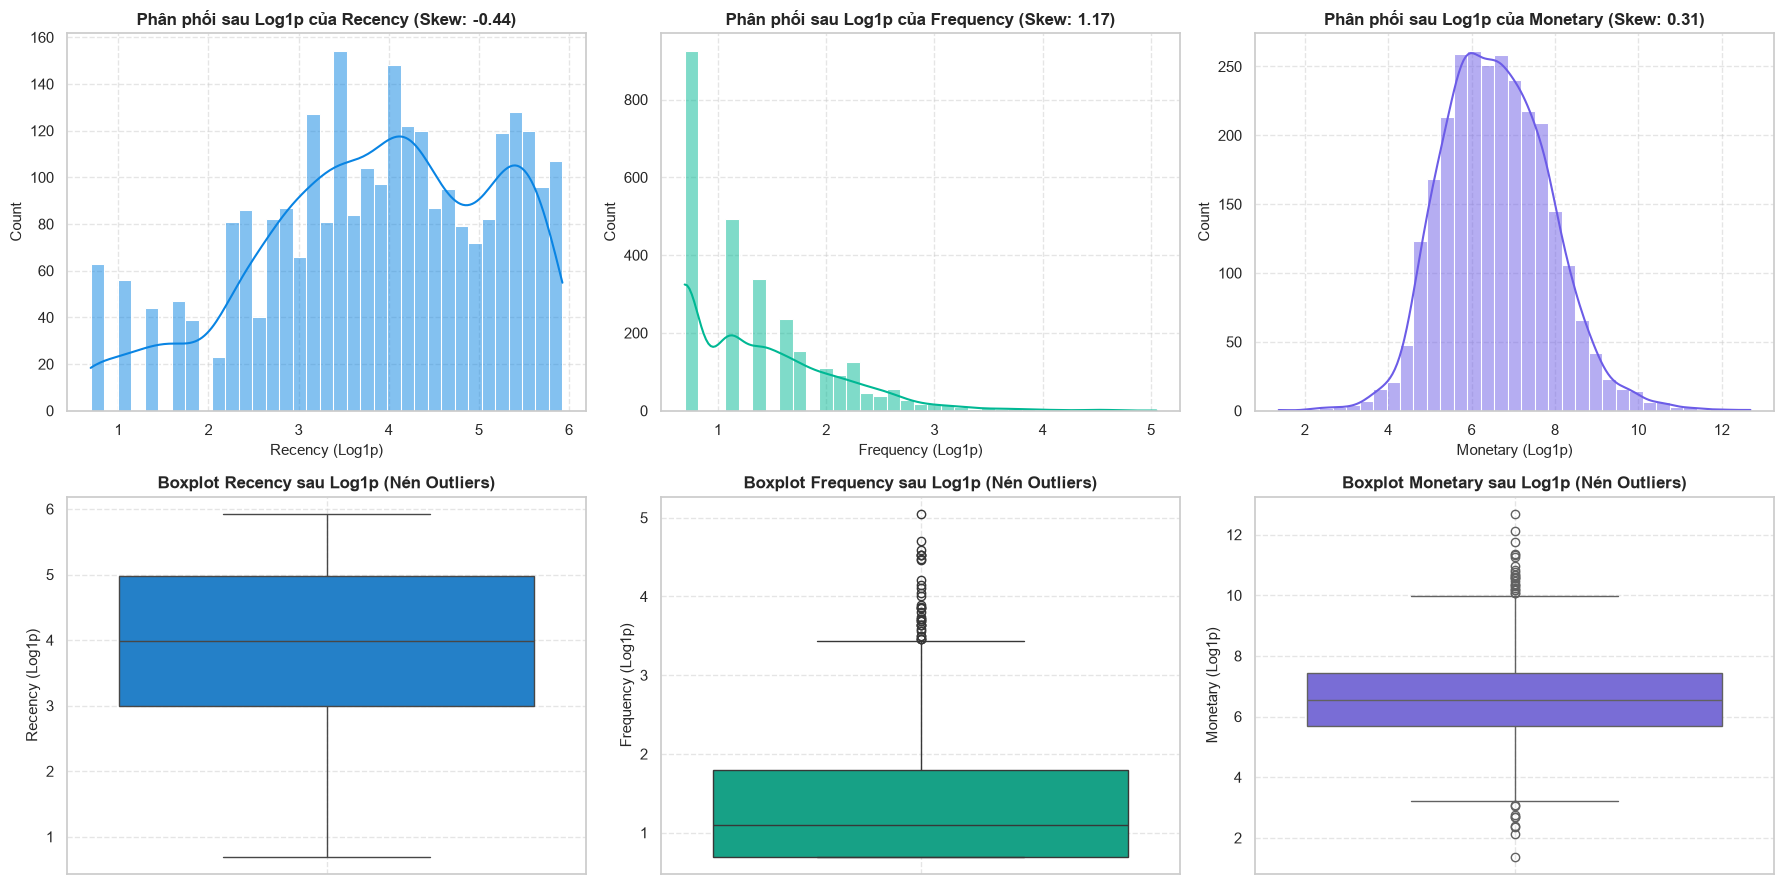

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
features = ['Recency', 'Frequency', 'Monetary']
colors = ['#0984e3', '#00b894', '#6c5ce7']

for i, col in enumerate(features):
    log_col = f'{col}_log'
    # 1. Histogram & KDE sau Log1p
    sns.histplot(train_rfm[log_col], kde=True, ax=axes[0, i], color=colors[i], bins=35)
    axes[0, i].set_title(f'Phân phối sau Log1p của {col} (Skew: {log_skew[log_col]:.2f})', fontweight='bold', fontsize=12)
    axes[0, i].set_xlabel(f'{col} (Log1p)', fontsize=11)
    axes[0, i].set_ylabel('Count', fontsize=11)
    axes[0, i].grid(True, linestyle='--', alpha=0.5)
    
    # 2. Boxplot sau Log1p
    sns.boxplot(y=train_rfm[log_col], ax=axes[1, i], color=colors[i])
    axes[1, i].set_title(f'Boxplot {col} sau Log1p (Nén Outliers)', fontweight='bold', fontsize=12)
    axes[1, i].set_ylabel(f'{col} (Log1p)', fontsize=11)
    axes[1, i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 7. Trực quan hóa ma trận tương quan & Không gian đặc trưng RFM

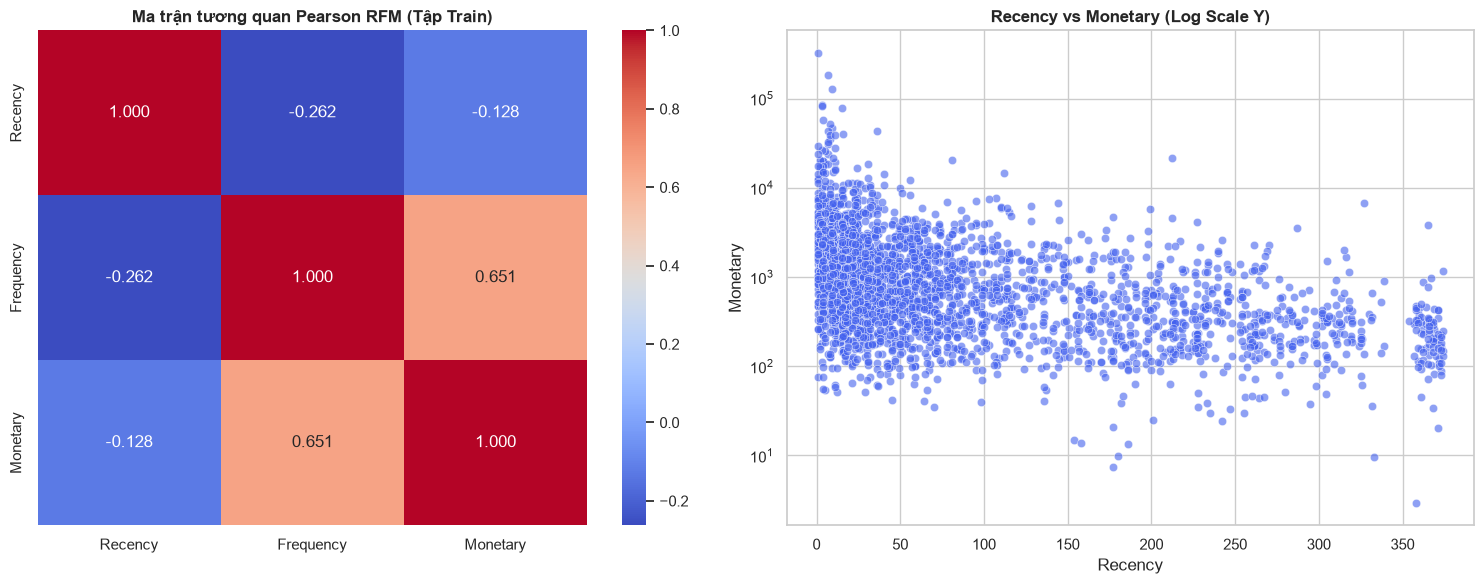

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Heatmap tương quan
rfm_corr = train_rfm[['Recency', 'Frequency', 'Monetary']].corr()
sns.heatmap(rfm_corr, annot=True, cmap="coolwarm", fmt=".3f", ax=ax1, cbar=True)
ax1.set_title("Ma trận tương quan Pearson RFM (Tập Train)", fontsize=12, fontweight='bold')

# Scatter Recency vs Monetary
sns.scatterplot(data=train_rfm, x="Recency", y="Monetary", alpha=0.6, ax=ax2, color="#4361ee")
ax2.set_yscale("log")
ax2.set_title("Recency vs Monetary (Log Scale Y)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 8. CELL XUẤT TẤT CẢ KẾT QUẢ ĐẶC TRƯNG RFM RA FILE
Cell này xuất toàn bộ các tệp dữ liệu đặc trưng RFM thô và đã xử lý `data/rfm_data.csv`, `rfm_train.csv`, `rfm_val.csv`, `rfm_test.csv`, bảng phân tích skewness, ma trận tương quan và báo cáo đặc trưng vào thư mục `outputs/`.

In [10]:
# ==============================================================================
# CELL XUẤT TẤT CẢ KẾT QUẢ ĐẶC TRƯNG RFM RA FILE
# ==============================================================================
output_dir = "03_Dac_trung/outputs" if os.path.exists("03_Dac_trung") else "EDA/03_Dac_trung/outputs"
data_dir = "data"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(data_dir, exist_ok=True)

# 1. Xuất các tập dữ liệu RFM vào thư mục data/
rfm.to_csv(os.path.join(data_dir, "rfm_data.csv"), index=False, encoding="utf-8-sig")
train_rfm.to_csv(os.path.join(data_dir, "rfm_train.csv"), index=False, encoding="utf-8-sig")
val_rfm.to_csv(os.path.join(data_dir, "rfm_val.csv"), index=False, encoding="utf-8-sig")
test_rfm.to_csv(os.path.join(data_dir, "rfm_test.csv"), index=False, encoding="utf-8-sig")

# 2. Xuất bảng thống kê mô tả RFM thô
rfm_desc.to_csv(os.path.join(output_dir, "rfm_descriptive_stats.csv"), encoding="utf-8-sig")

# 3. Xuất bảng so sánh Skewness trước và sau log
skew_compare_df.to_csv(os.path.join(output_dir, "rfm_skewness_comparison.csv"), index=False, encoding="utf-8-sig")

# 4. Xuất ma trận tương quan RFM
rfm_corr.to_csv(os.path.join(output_dir, "rfm_correlation_matrix.csv"), encoding="utf-8-sig")

# 5. Xuất báo cáo văn bản tóm tắt
lines_report_03 = [
    "="*80,
    "BÁO CÁO TỔNG HỢP GIAI ĐOẠN RÚT TRÍCH ĐẶC TRƯNG RFM (FEATURE REPORT)",
    "Dự án: Phân khúc khách hàng Online Retail II bằng RFM & Machine Learning",
    "="*80,
    "1. TỔNG QUAN BỘ ĐẶC TRƯNG RFM:",
    f"   - Tổng số khách hàng hợp lệ   : {len(rfm):,} khách hàng",
    f"   - Mốc thời gian Snapshot Date : {snapshot_date}",
    f"   - Độ lệch Skewness thô        : Recency={raw_skew['Recency']:.2f}, Frequency={raw_skew['Frequency']:.2f}, Monetary={raw_skew['Monetary']:.2f}",
    f"   - Độ lệch sau biến đổi log1p  : Recency={log_skew['Recency_log']:.2f}, Frequency={log_skew['Frequency_log']:.2f}, Monetary={log_skew['Monetary_log']:.2f}",
    "",
    "2. KẾT QUẢ PHÂN CHIA TẬP KHÁCH HÀNG RFM:",
    f"   - Tập RFM Train      : {len(train_rfm):,} khách hàng (~64.0%) -> 'data/rfm_train.csv'",
    f"   - Tập RFM Validation : {len(val_rfm):,} khách hàng (~16.0%) -> 'data/rfm_val.csv'",
    f"   - Tập RFM Test       : {len(test_rfm):,} khách hàng (~20.0%) -> 'data/rfm_test.csv'",
    "",
    "3. CHUẨN HÓA DỮ LIỆU (ANTI-DATA LEAKAGE):",
    f"   - StandardScaler Mean (Train) : {scaler.mean_}",
    f"   - StandardScaler Scale (Train): {scaler.scale_}",
    "="*80
]
report_text = chr(10).join(lines_report_03)
with open(os.path.join(output_dir, "rfm_report.txt"), "w", encoding="utf-8") as f:
    f.write(report_text)

print(f"💾 [XUẤT ĐẶC TRƯNG THÀNH CÔNG] Đã lưu các tệp đặc trưng RFM và báo cáo:")
print(f"   ✔ data/rfm_data.csv ({os.path.getsize(os.path.join(data_dir, 'rfm_data.csv')):,} bytes)")
print(f"   ✔ data/rfm_train.csv, rfm_val.csv, rfm_test.csv")
print(f"   ✔ {output_dir}/rfm_descriptive_stats.csv")
print(f"   ✔ {output_dir}/rfm_skewness_comparison.csv")
print(f"   ✔ {output_dir}/rfm_correlation_matrix.csv")
print(f"   ✔ {output_dir}/rfm_report.txt")

💾 [XUẤT ĐẶC TRƯNG THÀNH CÔNG] Đã lưu các tệp đặc trưng RFM và báo cáo:
   ✔ data/rfm_data.csv (576,828 bytes)
   ✔ data/rfm_train.csv, rfm_val.csv, rfm_test.csv
   ✔ 03_Dac_trung/outputs/rfm_descriptive_stats.csv
   ✔ 03_Dac_trung/outputs/rfm_skewness_comparison.csv
   ✔ 03_Dac_trung/outputs/rfm_correlation_matrix.csv
   ✔ 03_Dac_trung/outputs/rfm_report.txt


---
## 9. CELL XUẤT TẤT CẢ CÁC ẢNH BIỂU ĐỒ ĐẶC TRƯNG RA FILE
Cell này tự động xuất tất cả các biểu đồ phân phối, boxplot ngoại lai, đối chiếu sau biến đổi log, ma trận tương quan và không gian đặc trưng vào thư mục `figures/` của module và đồng bộ vào `figures/` của đề tài.

In [11]:
# ==============================================================================
# CELL XUẤT TẤT CẢ CÁC ẢNH BIỂU ĐỒ ĐẶC TRƯNG RA FILE
# ==============================================================================
local_fig_dir = "03_Dac_trung/figures" if os.path.exists("03_Dac_trung") else "EDA/03_Dac_trung/figures"
root_fig_dir = "figures"
os.makedirs(local_fig_dir, exist_ok=True)
os.makedirs(root_fig_dir, exist_ok=True)

saved_figs = []

def save_fig(fig, filename):
    p1 = os.path.join(local_fig_dir, filename)
    p2 = os.path.join(root_fig_dir, filename)
    fig.savefig(p1, dpi=300, bbox_inches='tight')
    fig.savefig(p2, dpi=300, bbox_inches='tight')
    plt.close(fig)
    saved_figs.append(filename)

# 1. Phân phối gốc và Boxplot RFM
fig1, axes = plt.subplots(2, 3, figsize=(18, 9))
features = ['Recency', 'Frequency', 'Monetary']
colors = ['#0984e3', '#00b894', '#6c5ce7']
for i, col in enumerate(features):
    sns.histplot(rfm[col], kde=True, ax=axes[0, i], color=colors[i], bins=40)
    axes[0, i].set_title(f'Phân phối gốc của {col} (Skew: {raw_skew[col]:.2f})', fontweight='bold')
    sns.boxplot(y=rfm[col], ax=axes[1, i], color=colors[i])
    axes[1, i].set_title(f'Boxplot {col} (Phát hiện Outliers)', fontweight='bold')
plt.tight_layout()
save_fig(fig1, 'fig01_rfm_raw_distribution.png')

# 2. Phân phối sau khi biến đổi Log (2 hàng x 3 cột: Histogram + KDE & Boxplot)
fig2, axes2 = plt.subplots(2, 3, figsize=(18, 9))
for i, col in enumerate(features):
    log_col = f'{col}_log'
    sns.histplot(train_rfm[log_col], kde=True, ax=axes2[0, i], color=colors[i], bins=35)
    axes2[0, i].set_title(f'Phân phối sau Log1p của {col} (Skew: {log_skew[log_col]:.2f})', fontweight='bold', fontsize=12)
    axes2[0, i].set_xlabel(f'{col} (Log1p)', fontsize=11)
    axes2[0, i].set_ylabel('Count', fontsize=11)
    axes2[0, i].grid(True, linestyle='--', alpha=0.5)
    
    sns.boxplot(y=train_rfm[log_col], ax=axes2[1, i], color=colors[i])
    axes2[1, i].set_title(f'Boxplot {col} sau Log1p (Nén Outliers)', fontweight='bold', fontsize=12)
    axes2[1, i].set_ylabel(f'{col} (Log1p)', fontsize=11)
    axes2[1, i].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig(fig2, 'fig02_rfm_log_distribution.png')

# 3. Ma trận tương quan và Scatter plot Recency vs Monetary
fig3, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(rfm_corr, annot=True, cmap="coolwarm", fmt=".3f", ax=ax1, cbar=True)
ax1.set_title("Ma trận tương quan Pearson RFM (Tập Train)", fontsize=12, fontweight='bold')
sns.scatterplot(data=train_rfm, x="Recency", y="Monetary", alpha=0.6, ax=ax2, color="#4361ee")
ax2.set_yscale("log")
ax2.set_title("Recency vs Monetary (Log Scale Y)", fontsize=12, fontweight='bold')
plt.tight_layout()
save_fig(fig3, 'fig03_rfm_correlation_and_scatter.png')

# 4. Trực quan hóa không gian 3D của RFM sau chuẩn hóa
fig4 = plt.figure(figsize=(10, 8))
ax4 = fig4.add_subplot(111, projection='3d')
sample_train = train_rfm.sample(min(1000, len(train_rfm)), random_state=42)
p = ax4.scatter(sample_train['Recency_scaled'], sample_train['Frequency_scaled'], sample_train['Monetary_scaled'],
                c=sample_train['Monetary_scaled'], cmap='viridis', alpha=0.7, edgecolors='w', s=40)
ax4.set_xlabel('Recency (Scaled)', fontweight='bold')
ax4.set_ylabel('Frequency (Scaled)', fontweight='bold')
ax4.set_zlabel('Monetary (Scaled)', fontweight='bold')
ax4.set_title('Không gian đặc trưng 3D của RFM sau chuẩn hóa (StandardScaler)', fontweight='bold')
fig4.colorbar(p, ax=ax4, shrink=0.6, label='Monetary (Scaled)')
plt.tight_layout()
save_fig(fig4, 'fig04_rfm_3d_feature_space.png')

print(f"🖼️ [XUẤT BIỂU ĐỒ THÀNH CÔNG] Đã lưu {len(saved_figs)} biểu đồ vào:")
print(f"   1. Thư mục module: '{local_fig_dir}'")
print(f"   2. Thư mục gốc  : '{root_fig_dir}'")
for fn in saved_figs:
    p = os.path.join(local_fig_dir, fn)
    print(f"   ✔ {fn} ({os.path.getsize(p):,} bytes)")

🖼️ [XUẤT BIỂU ĐỒ THÀNH CÔNG] Đã lưu 4 biểu đồ vào:
   1. Thư mục module: '03_Dac_trung/figures'
   2. Thư mục gốc  : 'figures'
   ✔ fig01_rfm_raw_distribution.png (373,252 bytes)
   ✔ fig02_rfm_log_distribution.png (420,342 bytes)
   ✔ fig03_rfm_correlation_and_scatter.png (910,421 bytes)
   ✔ fig04_rfm_3d_feature_space.png (1,139,674 bytes)
